# AA 279B - Homework 3 Problem 3

## Imports

In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
import numpy as np
from numpy.linalg import norm
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar, fsolve
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
from lamberthub import vallado2013
import plotly.graph_objects as go
from tqdm import tqdm

import astropy.units as u
from astropy.time import Time
from astropy.coordinates import GCRS, ITRS, CartesianRepresentation

## Constants

In [18]:
RAD_TO_SIDEREAL_HOUR = 24.0/np.pi/2.0
MIN_TO_SEC = 60
HOUR_TO_SEC = 60 * MIN_TO_SEC
DAY_TO_SEC = 24 * HOUR_TO_SEC

M_TO_KM = 1.0/1000

DEG_TO_RAD = np.pi/180.0
RAD_TO_DEG = 1/DEG_TO_RAD

# km3/m2
MU_EARTH = 398600.4418

# km
R_EARTH = 6378.137

# rad/s
W_EARTH = 0.0000729211585530

MIN_TO_SEC = 60

In [19]:
# For sidereal 

# 00:00 Jan 1 2014, UTC
t_utc_2014 = 1388534400 
theta_utc_2014 = 6.7045617 / RAD_TO_SIDEREAL_HOUR

# Launcher data
launch_lon = -122.081944 * DEG_TO_RAD
launch_lat = 37.389444 * DEG_TO_RAD
launch_alt = 11 * M_TO_KM

# Dove 3 Orbital Elements
dove_epoch_day_num = 21.68857885
dove_epoch_utc = (dove_epoch_day_num - 1) * DAY_TO_SEC + t_utc_2014
i_dove = 97.7791 * DEG_TO_RAD
raan_dove = 95.3093 * DEG_TO_RAD
e_dove = 0.0155616
aop_dove = 357.8679 * DEG_TO_RAD
M_dove = 2.1812 * DEG_TO_RAD
n_dove = 14.56715041 / DAY_TO_SEC * 2 * np.pi # rev/day --> rad/s

a_dove = (MU_EARTH / n_dove/n_dove)**((1/3)) # Calc

# Sim start
# 0100h on 23 January 2014 UTC
sim_start_utc = 1390467600

## Part a

In [20]:
def calc_theta_g(t_utc, omega = W_EARTH, theta_ref = theta_utc_2014, t_ref = t_utc_2014):
    """Simple rotation from Greenwich

    Parameters
    ----------
    t_utc : float
        seconds
    omega : float, optional
        default `W_EARTH`
    theta_ref : float, optional
        default `theta_utc_2014`
    t_ref : float, optional
        unix epoch of Jan 1, 2024, default `time_utc_2014`
        
    Returns
    ------
    theta_g : float
    """
    return theta_ref + omega * (t_utc - t_ref)

## Part b

In [21]:
def kepler(M, e):
    """Vallado 4e eq. 2-4 p. 45 (pdf p. 72)"""
    E = fsolve(lambda E: E - e*np.sin(E) - M, M)[0]
    return E

def dcm_x(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [1, 0, 0],
        [0, np.cos(theta), np.sin(theta)],
        [0, -np.sin(theta), np.cos(theta)]
    ])

def dcm_y(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [np.cos(theta), 0, -np.sin(theta)],
        [0, 1, 0],
        [np.sin(theta), 0, np.cos(theta)]
    ])
    
def dcm_z(theta):
    """theta: angle of frame 2 wrt frame 1"""
    return np.array([
        [np.cos(theta), np.sin(theta), 0],
        [-np.sin(theta), np.cos(theta), 0],
        [0, 0, 1]
    ])
    

def rv_from_coe(a, e, i, raan, aop, M, mu = MU_EARTH) -> tuple[np.ndarray, np.ndarray]:
    """Vallado 4e Algorithm 10 p. 118 (pdf p. 145)"""

    # semiparameter - Vallado 4e p. 96 (pdf p. 123)
    p = a*(1 - e*e)
    
    E = kepler(M,e)
    
    # true anomaly - Vallado 4e. eq. 2-10 p. 47 (pdf p. 74)
    nu = 2 * np.arctan2(
    np.sqrt(1 + e) * np.sin(E / 2),
    np.sqrt(1 - e) * np.cos(E / 2)
)
    r_pqw = np.array([
        p*np.cos(nu),
        p*np.sin(nu),
        0
    ]) / (1 + e*np.cos(nu))
    
    v_pqw = np.array([
        -np.sin(nu),
        e + np.cos(nu),
        0
    ]) * np.sqrt(mu/p)
    
    dcm_ijk_wrt_pqw = dcm_z(-raan) @ dcm_x(-i) @ dcm_z(-aop)
    r_ijk = dcm_ijk_wrt_pqw @ r_pqw
    v_ijk = dcm_ijk_wrt_pqw @ v_pqw

    return r_ijk, v_ijk
    

# Vallado 4e example 2-6 p. 119 (pdf p. 146)
assert np.allclose(
    np.array(rv_from_coe(
        a = 36126.6428348052,
        e = 0.83285,
        i = 87.87 * DEG_TO_RAD,
        raan = 227.89 * DEG_TO_RAD,
        aop = 53.38 * DEG_TO_RAD,
        M = 7.60494 * DEG_TO_RAD)),
    np.array([
        [6525.344, 6861.535, 6449.125],
        [4.902276, 5.533124, -1.975709]
    ]) 
)

## Part c

In [22]:
dt_launch = 2 * MIN_TO_SEC
dt_tof = 2 * MIN_TO_SEC
# MAX_LAUNCH_DELAY = 24 * HOUR_TO_SEC
# MAX_TOF = 120 * MIN_TO_SEC

MIN_LAUNCH_DELAY = 0
MAX_LAUNCH_DELAY = 6 * HOUR_TO_SEC
MIN_TOF = 0
MAX_TOF = 2 * HOUR_TO_SEC

t_arr_launch = np.arange(MIN_LAUNCH_DELAY, MAX_LAUNCH_DELAY + dt_launch, dt_launch)
t_arr_tofs = np.arange(MIN_TOF, MAX_TOF + dt_tof, dt_tof)


N_LAUNCHES = len(t_arr_launch)
N_TOFS = len(t_arr_tofs)

print(f"Total launch delays: {N_LAUNCHES}")
print(f"Total tof: {N_TOFS}")

Total launch delays: 181
Total tof: 61


### Time grid / search space

In [23]:
launch_grid, offset_grid = np.meshgrid(
    t_arr_launch,
    t_arr_tofs,
    indexing="ij"
)

# dimensions of [x_dim, y_dim]
intercept_grid = launch_grid + offset_grid
print(intercept_grid.shape)

# From beginning of ephemeris time
t_total_utc = np.unique(np.concatenate(
        (np.array(sorted(intercept_grid.ravel())),t_arr_launch)
    )) + sim_start_utc # all places to evaluate

time_pairs = np.stack([
    launch_grid.ravel(),
    intercept_grid.ravel()
], axis=1)

(181, 61)


In [24]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    colorscale="Viridis",
    colorbar=dict(title="Arrival time [s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch,
    y=t_arr_tofs,
    z=intercept_grid.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=0,
        end=np.max(intercept_grid),
        size=2500,
        labelfont=dict(size=10, color="black")
    )
))

fig.add_trace(go.Scatter(
    x=launch_grid.ravel(),
    y=offset_grid.ravel(),
    mode="markers",
    marker=dict(
        size=4,
        color="black",
        opacity=0.7
    ),
    name="Grid points"
))

fig.update_layout(
    xaxis_title="Launch time [s]",
    yaxis_title="TOF [s]",
    title="Search Space",
    width=2000,
    height=500
)

fig.update_xaxes(
    range=[np.min(t_arr_launch), np.max(t_arr_launch)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs), np.max(t_arr_tofs)],
    constrain="domain"
)

fig.show()

In [25]:
def plot_3d(t_arr, traces, labels="Orbit", title="3D Orbits", r_earth=R_EARTH):

    fig = go.Figure()

    # Earth
    u_ = np.linspace(0, 2*np.pi, 80)
    v_ = np.linspace(0, np.pi, 40)

    x_earth = r_earth * np.outer(np.cos(u_), np.sin(v_))
    y_earth = r_earth * np.outer(np.sin(u_), np.sin(v_))
    z_earth = r_earth * np.outer(np.ones_like(u_), np.cos(v_))

    fig.add_trace(go.Surface(
        x=x_earth,
        y=y_earth,
        z=z_earth,
        name="Earth",
        showscale=False,
        opacity=0.7,
        colorscale=[[0, "royalblue"], [1, "royalblue"]]
    ))

    # Allow a single (N,3) trajectory
    if isinstance(traces, np.ndarray) and traces.ndim == 2:
        traces = [traces]
        labels = [labels]

    # Multiple trajectories can have different lengths
    for trace, label in zip(traces, labels):
        trace = np.asarray(trace)


        cs_x = CubicSpline(t_arr, trace[:, 0])
        cs_y = CubicSpline(t_arr, trace[:, 1])
        cs_z = CubicSpline(t_arr, trace[:, 2])

        t_fine = np.linspace(t_arr[0], t_arr[-1], 1000)

        r_fine = np.column_stack((
            cs_x(t_fine),
            cs_y(t_fine),
            cs_z(t_fine)
        ))

        fig.add_trace(go.Scatter3d(
            x=r_fine[:, 0],
            y=r_fine[:, 1],
            z=r_fine[:, 2],
            mode="lines",
            name=f"{label} Trajectory",
            line=dict(width=5)
        ))

        fig.add_trace(go.Scatter3d(
            x=[r_fine[-1, 0]],
            y=[r_fine[-1, 1]],
            z=[r_fine[-1, 2]],
            mode="markers",
            name=f"{label} Final position",
            marker=dict(size=6)
        ))

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="x [km]",
            yaxis_title="y [km]",
            zaxis_title="z [km]",
            aspectmode="data"
        ),
        template="plotly_white",
        legend=dict(x=0.02, y=0.98),
        height=900
    )

    fig.show()

### Launch positions

In [26]:
"""
Inputs:
- Time 
- Lat/lon

"""

def calc_ecef_from_lat_lon_alt(lat, lon, alt_km = 0, deg = False, r_body_km = R_EARTH):
    if deg:
        lat *= DEG_TO_RAD
        lon *= DEG_TO_RAD
        
    rho = r_body_km + alt_km
    
    r_ecef = np.array([
        rho * np.cos(lat) * np.cos(lon),
        rho * np.cos(lat) * np.sin(lon),
        rho * np.sin(lat)
    ])
    v_ecef = np.cross([0,0,W_EARTH], r_ecef)
    
    return r_ecef, v_ecef

def calc_eci_from_ecef(r_ecef, v_ecef, t_utc):
    """Somewhat simplified version of itrf-gcrs in Vallado 4e Section 3.7 pp. 203-"""
    # Earth rotation angle
    theta_ecef_wrt_eci = calc_theta_g(t_utc)
    
    dcm_eci_wrt_ecef = dcm_z(theta_ecef_wrt_eci).T
    
    r_eci = dcm_eci_wrt_ecef @ r_ecef
    v_eci = dcm_eci_wrt_ecef @ v_ecef
    
    return r_eci, v_eci

In [27]:
## Actual calculation

def launch_eci(t_arr_utc, lat, lon, alt):
    launch_r_ecef, launch_v_ecef = calc_ecef_from_lat_lon_alt(lat, lon, alt)
    
    launch_arr_eci = np.array([calc_eci_from_ecef(launch_r_ecef, launch_v_ecef, t) for t in t_arr_utc])
    launch_r_eci = launch_arr_eci[:,0,:]
    launch_v_eci = launch_arr_eci[:,1,:]
    return launch_r_eci, launch_v_eci

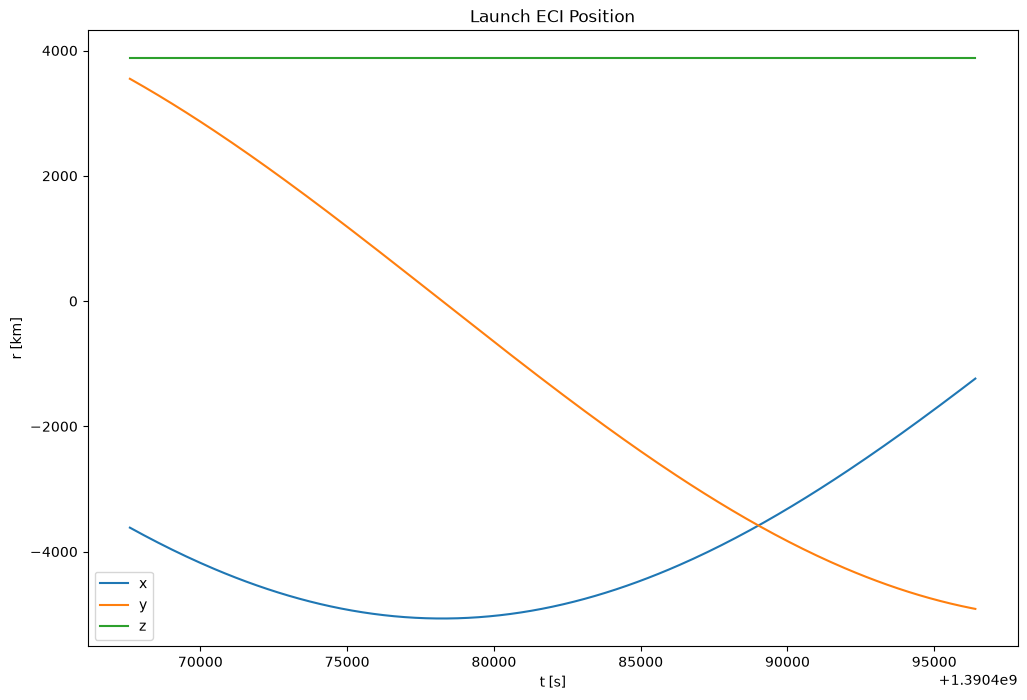

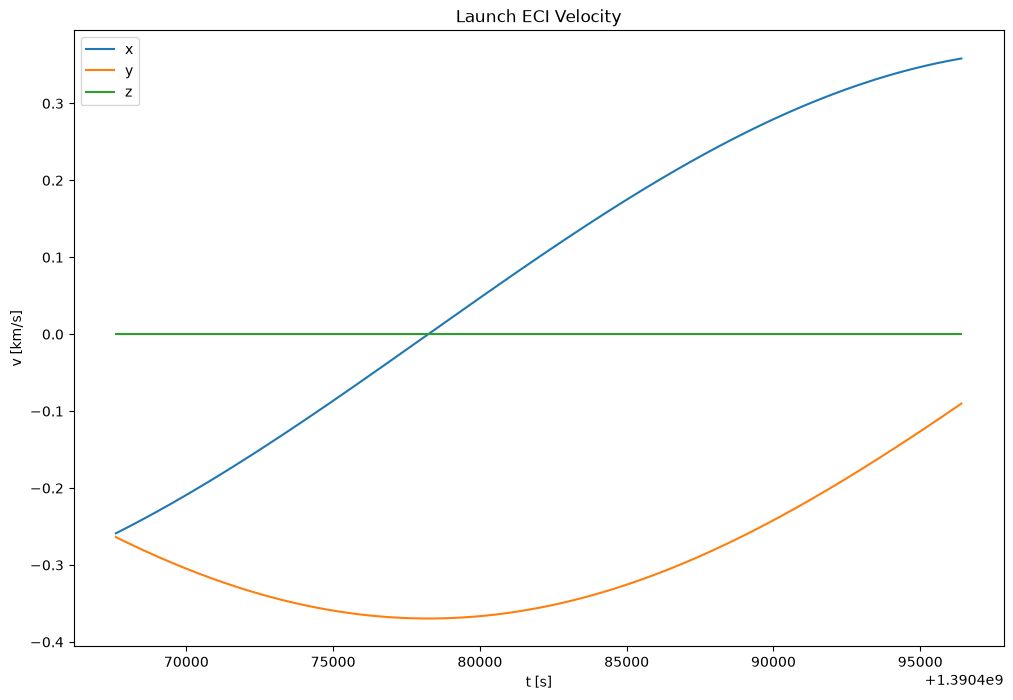

In [28]:
launch_r_eci, launch_v_eci = launch_eci(t_total_utc, launch_lat, launch_lon, launch_alt)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, launch_r_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_r_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, launch_v_eci[:,0], label = "x")
plt.plot(t_total_utc, launch_v_eci[:,1], label = "y")
plt.plot(t_total_utc, launch_v_eci[:,2], label = "z")
plt.legend()
plt.show()

In [29]:
plot_3d(t_total_utc, launch_r_eci, "Launcher", title="3D Launch Site Position")

### Sat positions

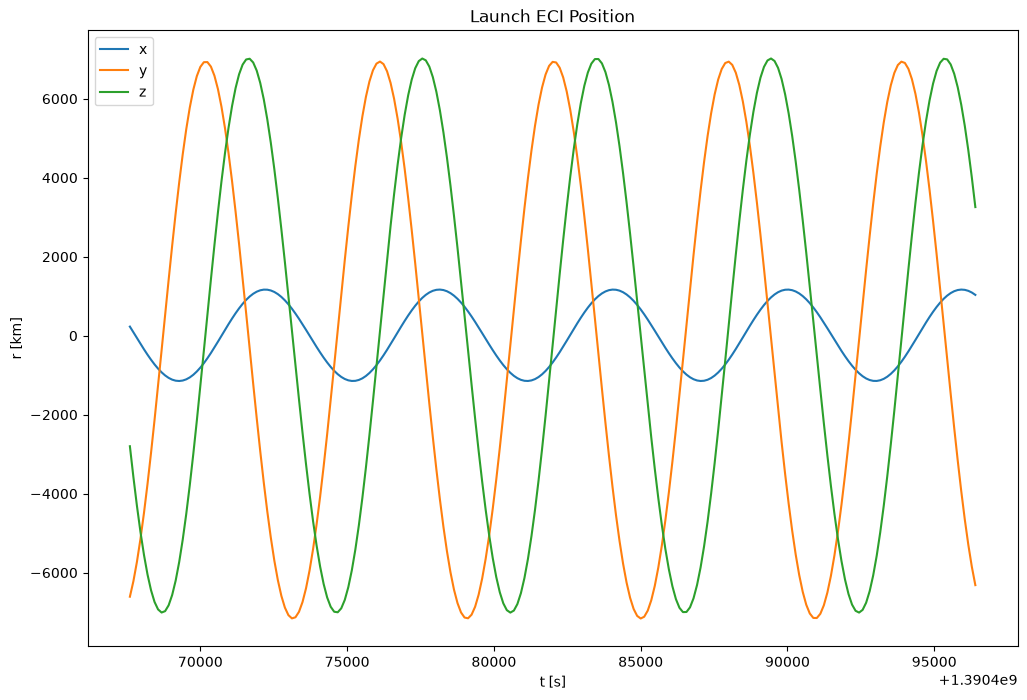

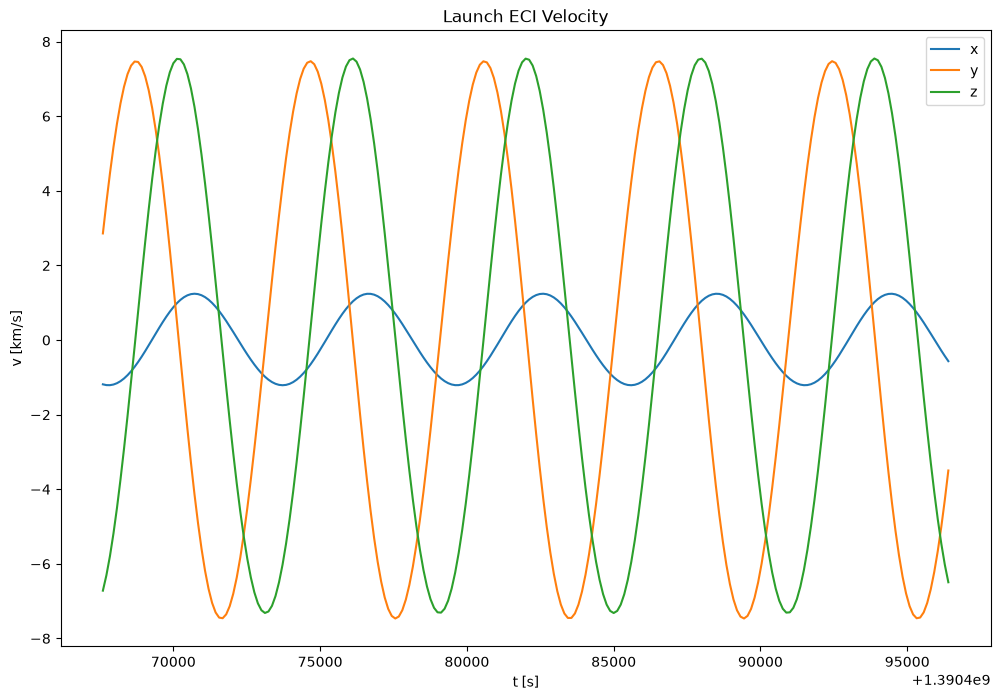

In [30]:
## Sat functions
def dove3_rv_eci(t_arr, t0 = dove_epoch_utc) -> np.ndarray | tuple[np.ndarray, np.ndarray]:
    M_new = (M_dove + n_dove*(t_arr - t0))
    rv = np.array([rv_from_coe(a_dove,e_dove,i_dove,raan_dove,aop_dove,M) for M in M_new])
    r = rv[:,0,:]
    v = rv[:,1,:]
    return r,v

dove3_r_eci, dove3_v_eci = dove3_rv_eci(t_total_utc)

plt.figure(figsize=(12,8))
plt.title("Launch ECI Position")
plt.xlabel("t [s]")
plt.ylabel("r [km]")
plt.plot(t_total_utc, dove3_r_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_r_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_r_eci[:,2], label = "z")
plt.legend()
plt.show()

plt.figure(figsize=(12,8))
plt.title("Launch ECI Velocity")
plt.xlabel("t [s]")
plt.ylabel("v [km/s]")
plt.plot(t_total_utc, dove3_v_eci[:,0], label = "x")
plt.plot(t_total_utc, dove3_v_eci[:,1], label = "y")
plt.plot(t_total_utc, dove3_v_eci[:,2], label = "z")
plt.legend()
plt.show()

### Both positions

In [31]:
plot_3d(t_total_utc, [launch_r_eci, dove3_r_eci], ["Launcher", "Dove 3"], title="3D Launch Site Position")

### Calculation

In [32]:
# Search space
dv1_arr = np.full((N_LAUNCHES, N_TOFS, 3), np.nan)
dv2_arr = np.full((N_LAUNCHES, N_TOFS, 3), np.nan)
print(f"Search space: {dv1_arr.shape}, with {N_LAUNCHES * N_TOFS} total")

Search space: (181, 61, 3), with 11041 total


In [ ]:
def find_launch_rv(t,t_arr,r_arr,v_arr):
    i = np.argmin(np.abs(t_arr - t))
    return r_arr[i], v_arr[i]

for launch_num in tqdm(range(N_LAUNCHES)):
    t_launch = t_arr_launch[launch_num]
    # print(f"Launch offset: {t_launch}")
    for tof_num in range(N_TOFS):
        tof = t_arr_tofs[tof_num]
        t_intercept = t_launch + tof
        # print(f"\tIntercept time: {t_intercept}")
        
        
        r_launch, v_launch = find_launch_rv(t_launch + sim_start_utc, t_total_utc, launch_r_eci, launch_v_eci)
        r_sat, v_sat = find_launch_rv(t_intercept + sim_start_utc, t_total_utc, dove3_r_eci, dove3_v_eci)
        
        # Parabola/hyperbola check (short way)
        c = norm(r_launch - r_sat)
        s = (norm(r_launch) + norm(r_sat) + c) / 2
        dt_parabola = 1/3 * np.sqrt(2/MU_EARTH) * (s**(3/2) - (s-c)**(3/2))
        if tof <= dt_parabola:
            continue
        
        # Call solver
        try:
            v1_after, v2_after = vallado2013(MU_EARTH, r_launch, r_sat, tof)
        except ValueError:
            continue
        

# Earth-impact check
        if np.dot(r_launch, v1_after) < 0 and np.dot(r_sat, v2_after) > 0:
            e_vec = (
                (norm(v1_after)**2 - MU_EARTH / norm(r_launch)) * r_launch
                - np.dot(r_launch, v1_after) * v1_after
            ) / MU_EARTH

            r_perigee = (
                norm(np.cross(r_launch, v1_after))**2
                / (MU_EARTH * (1 + norm(e_vec)))
            )

            if r_perigee <= R_EARTH:
                continue
        
        dv1 = v1_after - v_launch
        dv2 = v_sat - v2_after
        # print()
        
        
            
        dv1_arr[launch_num, tof_num] = dv1
        dv2_arr[launch_num, tof_num] = dv2



100%|██████████| 181/181 [00:04<00:00, 37.80it/s] 


In [35]:
dv1_arr_mag = np.apply_along_axis(norm, 2, dv1_arr)
dv2_arr_mag = np.apply_along_axis(norm, 2, dv2_arr)

dv_arr_mag = dv1_arr_mag + dv2_arr_mag

In [ ]:

fig = go.Figure()

# plotly expects [y_dim, x_dim] so z.T
fig.add_trace(go.Heatmap(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr_mag.T,
    colorscale="Viridis",
    colorbar=dict(title="Departure dv [km/s]"),
    opacity=0.8,
))

fig.add_trace(go.Contour(
    x=t_arr_launch / MIN_TO_SEC,
    y=t_arr_tofs / MIN_TO_SEC,
    z=dv_arr_mag.T,
    showscale=False,
    line=dict(width=2, color="black"),
    contours=dict(
        coloring="lines",
        showlabels=True,
        start=0,
        end=np.max(dv_arr_mag),
        size=1,
        labelfont=dict(size=10, color="black")
    )
))

# fig.add_trace(go.Scatter(
#     x=launch_grid.ravel(),
#     y=offset_grid.ravel(),
#     mode="markers",
#     marker=dict(
#         size=4,
#         color="black",
#         opacity=0.7
#     ),
#     name="Grid points"
# ))

fig.update_layout(
    xaxis_title="Launch time [s]",
    yaxis_title="TOF [min]",
    title="dv1",
    width=1000,
    height=1000
)

fig.update_xaxes(
    range=[np.min(t_arr_launch / MIN_TO_SEC), np.max(t_arr_launch / MIN_TO_SEC)],
    constrain="domain"
)

fig.update_yaxes(
    range=[np.min(t_arr_tofs / MIN_TO_SEC), np.max(t_arr_tofs / MIN_TO_SEC)],
    constrain="domain"
)

fig.show()